In [1]:
# Реализовать преобразование Хаара (3 ступени сжатия)
# Исходное изображение 512x512

In [2]:
import numpy as np
import cv2
from matplotlib import pyplot as plt
import copy

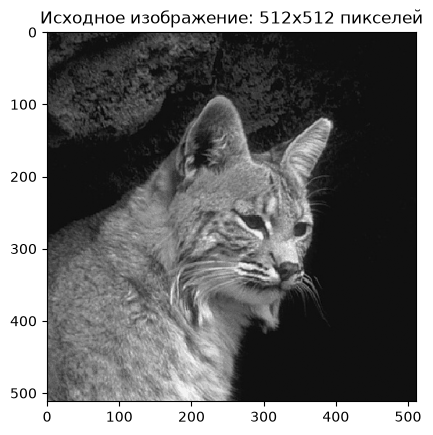

In [3]:
image = cv2.imread('8.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
height, width = image_gray.shape
plt.title(f'Исходное изображение: {width}x{height} пикселей')
plt.imshow(image_gray, cmap='gray')

In [15]:
def haar2d(img):
    # Обработка по строкам
    row_low = (img[:, 0::2] + img[:, 1::2]) / 2.0
    row_high = (img[:, 0::2] - img[:, 1::2]) / 2.0

    # Обработка по столбцам
    LL = (row_low[0::2, :] + row_low[1::2, :]) / 2.0
    LH = (row_low[0::2, :] - row_low[1::2, :]) / 2.0

    HL = (row_high[0::2, :] + row_high[1::2, :]) / 2.0
    HH = (row_high[0::2, :] - row_high[1::2, :]) / 2.0

    top = np.hstack((LL, HL))
    bottom = np.hstack((LH, HH))

    return np.vstack((top, bottom))

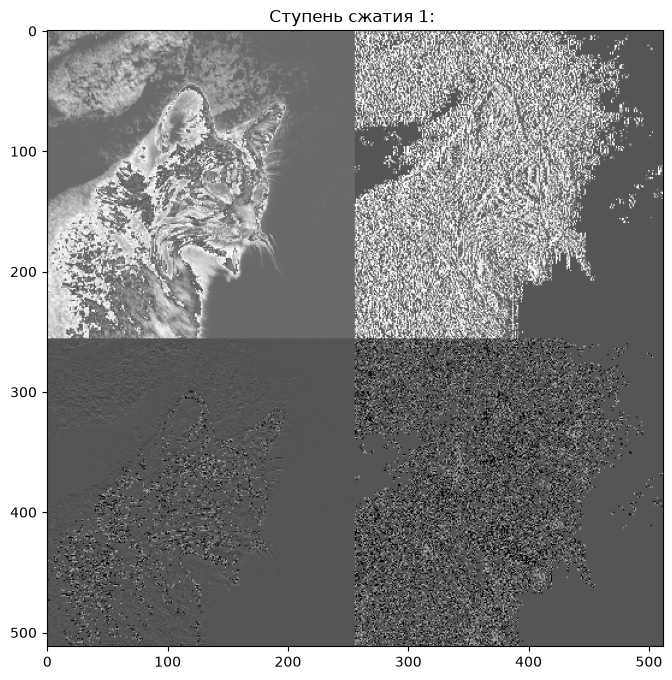

In [18]:
image_float = image_gray.copy()
step1 = haar2d(image_float)

plt.figure(figsize=(8, 8))
plt.imshow(step1, cmap='gray', vmin=step1.min(), vmax=step1.max())
plt.title('Ступень сжатия 1: ')
plt.show()

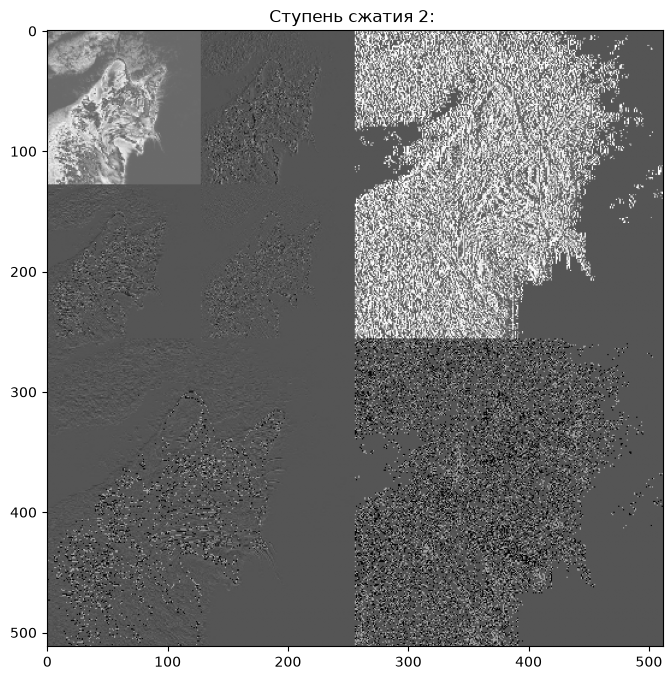

In [20]:
step2 = copy.deepcopy(step1);
step2[0:height//2, 0:width//2] = haar2d(step2[0:height//2, 0:width//2])
plt.figure(figsize=(8, 8))
plt.imshow(step2, cmap='gray', vmin=step2.min(), vmax=step2.max())
plt.title('Ступень сжатия 2: ')
plt.show()

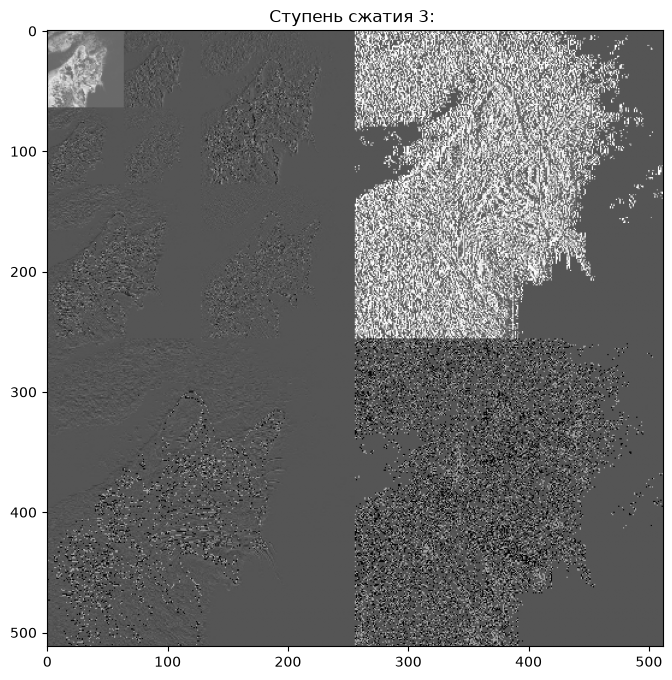

In [21]:
step3 = copy.deepcopy(step2)
step3[0:height//4, 0:width//4] = haar2d(step3[0:height//4, 0:width//4])
plt.figure(figsize=(8, 8))
plt.imshow(step3, cmap='gray', vmin=step3.min(), vmax=step3.max())
plt.title('Ступень сжатия 3: ')
plt.show()